# 08 · Canonical records, labels and the leakage-controlled co-citation graph (Phase 5)

Input: the citer pool and corpus from notebook 07. Design: `research/audit/PHASE5_DESIGN.md`.

1. **Canonical records.** Duplicate OpenAlex records (same DOI, or same title within a year) are merged in the corpus and in the labels, so a method is never scored down for retrieving a positive's other record.
2. **Labels.** Phase 5 positives are the v2 positives, mapped to canonical ids. Positives that are gone from OpenAlex or lack an abstract are dropped. So is the dev copy `W3012006042` of a test query.
3. **Query duplicates (rule R3).** Pool works that duplicate a query record by DOI, exact title (any year, so earlier versions of living reviews count) or near-title with a shared author.
4. **Graph.** A citer × document matrix over the corpus. Each row keeps its date and its kind (pool, query record, query duplicate), so rules R1–R5 are row masks applied per query (`src/cograph.py`).
5. **Reachability under each rule.** The share of positives that some allowed citer cites, with each rule switched off in turn. This bounds what graph expansion can recover, before any method runs.
6. **Unit tests** for every rule (`tests/test_cograph.py`).

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
DROP_QUERIES = {"https://openalex.org/W3012006042": "dev copy of test query W4247191450 (decision 6)"}
MIN_POSITIVES = 3  # same rule as v2

In [3]:
import glob
import json

from src.corpus import CITERS, WORKS, citer_pool
from src.eval_v2 import eligible
from src.openalex import normalize_work
from src.pipeline_v2 import load_eval_sets, load_v1_queries

manifest = json.loads((RESEARCH / "v2" / "corpus" / "corpus_manifest.json").read_text())
works = {}
with WORKS.open() as f:
    for line in f:
        w = json.loads(line)
        works[w["id"]] = w
ds = load_eval_sets("random")
sets, splits = ds["sets"], ds["splits"]
query_ids = {q["id"] for q in load_v1_queries()}
pool = citer_pool([json.loads(Path(p).read_text()) for p in sorted(glob.glob(str(CITERS / "*.json")))])
print(f"corpus ids {len(manifest['corpus_ids'])}, cached works {len(works)}, citer pool {len(pool)}, "
      f"query records with a cached work {len(query_ids & set(works))}/{len(query_ids)}")

corpus ids 12096, cached works 16888, citer pool 13572, query records with a cached work 174/174


### 1 · Canonical records

In [4]:
from collections import defaultdict

from src.cograph import canonical_map

v2_positives = {p for s in sets for p in s["positives"]}
records = {}
for pid in manifest["corpus_ids"]:
    rec = normalize_work(works[pid])
    records[pid] = {**rec, "doi": works[pid].get("doi")}
canon = canonical_map(records, prefer=v2_positives)

groups = defaultdict(list)
for pid, c in canon.items():
    groups[c].append(pid)
dup_groups = {c: sorted(m) for c, m in groups.items() if len(m) > 1}
print(f"{len(records)} records -> {len(groups)} canonical works; {len(dup_groups)} duplicate groups "
      f"({sum(len(m) for m in dup_groups.values()) - len(dup_groups)} records merged)")
print(f"groups with two or more v2 positives: {sum(len(set(m) & v2_positives) > 1 for m in dup_groups.values())}; "
      f"groups joining a positive and a non-positive: {sum(0 < len(set(m) & v2_positives) < len(m) for m in dup_groups.values())}")
for c, m in list(dup_groups.items())[:8]:
    print("  ", [x.rsplit('/', 1)[1] for x in m], "|", records[c]["publication_date"][:4], records[c]["title"][:70])

12096 records -> 11968 canonical works; 119 duplicate groups (128 records merged)
groups with two or more v2 positives: 10; groups joining a positive and a non-positive: 12
   ['W1515587369', 'W4299588845'] | 2017 The Discovery of Grounded Theory
   ['W1517222036', 'W24060287'] | 2003 Stability of SARS Coronavirus in Human Specimens and Environment and I
   ['W1534533078', 'W4254896200'] | 2011 Physical interventions to interrupt or reduce the spread of respirator
   ['W1545460766', 'W2000380427'] | 2014 A primer on partial least squares structural equation modeling (PLS-SE
   ['W1554663460', 'W4388297464'] | 1994 Neural networks for pattern recognition
   ['W1605824561', 'W2608014122'] | 2006 Constructing grounded theory : a practical guide through qualitative a
   ['W1606697907', 'W2022101730'] | 1992 Infectious Diseases of Humans: Dynamics and Control
   ['W1651586605', 'W4296886862'] | 2007 Applications of machine learning in cancer prediction and prognosis.


In [5]:
doc_ids = sorted({c for c in canon.values() if eligible(records[c])})
print(f"candidate corpus after canonicalization and eligibility: {len(doc_ids)} works")

candidate corpus after canonicalization and eligibility: 11967 works


### 2 · Labels

In [6]:
doc_set = set(doc_ids)
labels, dropped, lost = {}, [], []
for s in sets:
    qid = s["pi_id"]
    if qid in DROP_QUERIES:
        dropped.append({"pi_id": qid, "reason": DROP_QUERIES[qid]})
        continue
    pos = []
    for p in s["positives"]:
        c = canon.get(p)
        if c is None or c not in doc_set:
            lost.append({"pi_id": qid, "positive": p, "split": splits[qid],
                         "reason": "not in OpenAlex" if p not in works else "no abstract"})
        elif c not in pos:
            pos.append(c)
    if len(pos) < MIN_POSITIVES:
        dropped.append({"pi_id": qid, "reason": f"{len(pos)} positives left"})
        continue
    labels[qid] = {"split": splits[qid], "date": s["pi_date"], "title": s["pi_title"], "positives": sorted(pos)}

lab = pd.DataFrame([{"split": v["split"], "n_pos": len(v["positives"])} for v in labels.values()])
print(lab.groupby("split").n_pos.agg(["size", "sum", "median", "min", "max"]))
print(f"v2 positive slots {sum(len(s['positives']) for s in sets)} -> Phase 5 {lab.n_pos.sum()}; "
      f"positives dropped: {len(lost)}; merged as duplicates: "
      f"{sum(len(s['positives']) for s in sets if s['pi_id'] in labels) - lab.n_pos.sum() - sum(l['pi_id'] in labels for l in lost)}")
print(pd.DataFrame(lost).to_string(index=False))
print(pd.DataFrame(dropped).to_string(index=False))

       size  sum  median  min  max
split                             
dev      48  364     7.0    3   13
test    118  855     7.0    3   13
v2 positive slots 1247 -> Phase 5 1219; positives dropped: 5; merged as duplicates: 9
                           pi_id                         positive split          reason
https://openalex.org/W3005073185 https://openalex.org/W2951482518  test not in OpenAlex
https://openalex.org/W3173556047 https://openalex.org/W3168183489  test not in OpenAlex
https://openalex.org/W4388291555 https://openalex.org/W3012048021   dev     no abstract
https://openalex.org/W4389523957 https://openalex.org/W3090325631  test not in OpenAlex
https://openalex.org/W4389523957 https://openalex.org/W4226369848  test not in OpenAlex
                           pi_id                                          reason
https://openalex.org/W3012006042 dev copy of test query W4247191450 (decision 6)
https://openalex.org/W4388291555                                2 positives left


### 3 · Query duplicates in the citer pool (R3)

Every match is listed so the rule can be checked by eye.

In [7]:
from src.cograph import author_ids, query_duplicates

queries = {q: works[q] for q in query_ids}
qdups = query_duplicates(pool, queries)
rows = []
for cid, (qid, reason) in sorted(qdups.items(), key=lambda x: (x[1][1], x[1][0])):
    c, q = pool[cid], queries[qid]
    rows.append({"reason": reason, "citer": cid.rsplit("/", 1)[1], "citer_date": c["publication_date"],
                 "query": qid.rsplit("/", 1)[1], "query_date": q["publication_date"],
                 "shared_authors": len(author_ids(c) & author_ids(q)),
                 "shared_refs": f"{len(set(c['referenced_works']) & set(q['referenced_works']))}/{len(q['referenced_works'])}",
                 "title": c["title"][:60]})
qd = pd.DataFrame(rows)
print(qd.reason.value_counts().to_dict(), "| query records in the pool:", len(set(pool) & query_ids))
qd

{'title': 12, 'near-title': 7, 'doi': 1} | query records in the pool: 3


,reason,citer,citer_date,query,query_date,shared_authors,shared_refs,title
0,doi,W4229036110,2021-05-07,W3159396736,2022-01-12,1,9/11,Congenital Adrenal Hyperplasia—Current Insight...
1,near-title,W2921679472,2019-03-15,W3178636644,2021-06-01,3,2/13,A technical comparison of three low earth orbi...
2,near-title,W2984194970,2019-11-11,W3199710005,2021-09-16,13,7/14,THE CONCISE GUIDE TO PHARMACOLOGY 2019/20: G p...
3,near-title,W2765684626,2017-10-21,W3199710005,2021-09-16,10,7/14,THE CONCISE GUIDE TO PHARMACOLOGY 2017/18: G p...
4,near-title,W4206138109,2020-06-18,W4205754343,2021-09-08,9,4/10,International Committee for Monitoring Assiste...
5,near-title,W4236533978,2014-05-02,W4205754343,2021-09-08,5,0/10,International Committee for Monitoring Assiste...
6,near-title,W4231523544,2014-12-13,W4205754343,2021-09-08,6,2/10,International Committee for Monitoring Assiste...
7,near-title,W4231894124,2021-04-27,W4205754343,2021-09-08,8,5/10,International Committee for Monitoring Assiste...
8,title,W3212080866,2021-11-06,W3212282753,2021-11-10,24,8/10,STROCSS 2021: Strengthening the reporting of c...
9,title,W4241095211,2021-10-01,W3212282753,2021-11-10,2,8/10,STROCSS 2021: strengthening the reporting of c...


### 4 · Graph

In [8]:
from src.cograph import build_graph

citers = {**pool, **{q: works[q] for q in query_ids}}  # query records are rows too, so R1/R2/R5 are testable
g = build_graph(citers, doc_ids, canon, query_ids, set(qdups))
nnz_rows = np.asarray(g.C.sum(1)).ravel()
pool_rows = ~g.is_query & ~g.is_query_dup
print(f"{g.C.shape[0]} citer rows ({g.is_query.sum()} query records, {g.is_query_dup.sum()} query duplicates), "
      f"{g.C.shape[1]} docs, {g.C.nnz} citation edges")
print(f"corpus references per pool citer: median {np.median(nnz_rows[pool_rows]):.0f}, "
      f"mean {nnz_rows[pool_rows].mean():.1f}; pool citers citing no corpus work: {(nnz_rows[pool_rows] == 0).sum()}")

13743 citer rows (174 query records, 20 query duplicates), 11967 docs, 127908 citation edges
corpus references per pool citer: median 5, mean 9.3; pool citers citing no corpus work: 2012


### 5 · Reachability of positives under each rule

A positive is *reachable* for its query if at least one allowed citer cites it. Graph expansion cannot recover an unreachable positive. Each row switches one rule off. The canary adds the query's own reference list, so every positive must become reachable.

In [9]:
from src.cograph import Rules

CONDITIONS = {
    "all rules (normal)": Rules(),
    "R3 off: keep query duplicates": Rules(drop_query_dups=False),
    "R4 off: allow later citers": Rules(temporal=False),
    "R5 off: allow other query records": Rules(drop_query_records=False),
    "R3–R5 off": Rules(temporal=False, drop_query_dups=False, drop_query_records=False),
    "canary: add the query's own references": Rules(canary=True),
}
idx = g.doc_index
reach = []
for qid, lab_q in labels.items():
    cols = [idx[p] for p in lab_q["positives"]]
    for name, rules in CONDITIONS.items():
        mask = g.allowed(qid, lab_q["date"], rules)
        deg = np.asarray(g.C[mask][:, cols].sum(0)).ravel()
        reach.append({"pi_id": qid, "split": lab_q["split"], "condition": name,
                      "n_pos": len(cols), "reachable": int((deg > 0).sum())})
reach = pd.DataFrame(reach)
reach_tab = (reach.groupby(["condition", "split"])[["n_pos", "reachable"]].sum()
             .assign(share=lambda d: (d.reachable / d.n_pos).round(3)).unstack("split"))
reach_tab.loc[list(CONDITIONS)]

n_pos      reachable       share       
split                                    dev test       dev test    dev   test
condition                                                                     
all rules (normal)                       364  855       227  542  0.624  0.634
R3 off: keep query duplicates            364  855       231  558  0.635  0.653
R4 off: allow later citers               364  855       244  583  0.670  0.682
R5 off: allow other query records        364  855       231  543  0.635  0.635
R3–R5 off                                364  855       248  599  0.681  0.701
canary: add the query's own references   364  855       364  855  1.000  1.000

In [10]:
assert (reach[reach.condition.str.startswith("canary")].pipe(lambda d: d.reachable == d.n_pos)).all(), \
    "canary must make every positive reachable"
print("canary check passed: every positive is reachable when the query's own references are added")

canary check passed: every positive is reachable when the query's own references are added


### 6 · Membership asymmetry

Non-positives entered the corpus because at least 5 pool citers cite them, while positives were added whatever their degree (decision 3). Degree alone therefore separates the two groups to some extent. Notebook 09 measures this with a degree-only ranker; here we only describe it, using all pool citers (no date filter).

In [11]:
pos_all = {p for v in labels.values() for p in v["positives"]}
deg = g.degree(pool_rows)
is_pos = np.array([d in pos_all for d in doc_ids])
deg_tab = pd.DataFrame({"group": np.where(is_pos, "positives", "non-positives"), "degree": deg})
print(deg_tab.groupby("group").degree.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
print(f"positives with degree 0: {(deg[is_pos] == 0).mean():.1%}; non-positives with degree < 5 after removing "
      f"query records and duplicates: {(deg[~is_pos] < 5).sum()}")

                 count  mean   std  min  10%  25%  50%   75%   90%    max
group                                                                    
non-positives  10805.0  10.5  12.7  0.0  5.0  5.0  7.0  11.0  18.0  458.0
positives       1162.0  11.5  35.4  0.0  0.0  0.0  2.0   8.0  24.0  505.0
positives with degree 0: 33.5%; non-positives with degree < 5 after removing query records and duplicates: 48


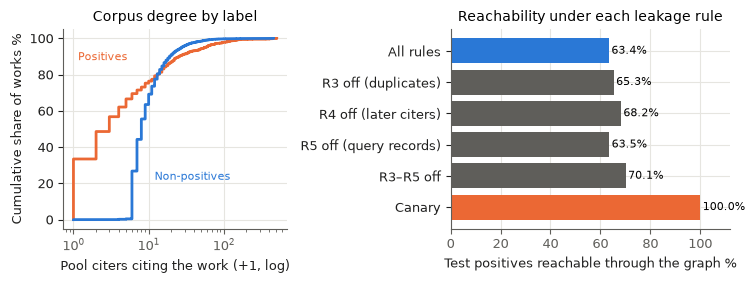

In [12]:
import matplotlib.pyplot as plt

from src.figures import INK_2, SLOTS

fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for name, sel, color, xy in (("Positives", is_pos, SLOTS[1], (1.15, 88)), ("Non-positives", ~is_pos, SLOTS[0], (12, 22))):
    x = np.sort(deg[sel] + 1)
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y * 100, where="post", color=color)
    ax.text(*xy, name, color=color, fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Pool citers citing the work (+1, log)")
ax.set_ylabel("Cumulative share of works %")
ax.set_title("Corpus degree by label")

ax = axes[1]
test = reach_tab.xs("test", axis=1, level="split")["share"].loc[list(CONDITIONS)] * 100
names = ["All rules", "R3 off (duplicates)", "R4 off (later citers)", "R5 off (query records)", "R3–R5 off", "Canary"]
colors = [SLOTS[0]] + [INK_2] * 4 + [SLOTS[1]]
ax.barh(range(len(test)), test.values, color=colors)
for i, v in enumerate(test.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_yticks(range(len(test)), names)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("Test positives reachable through the graph %")
ax.set_title("Reachability under each leakage rule")
fig.tight_layout()
save(fig, "08_graph_degree_reachability")
plt.show()

### 7 · Unit tests for the leakage rules

In [13]:
import subprocess

res = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"], cwd=RESEARCH, capture_output=True, text=True)
print(res.stdout[-1500:])
assert res.returncode == 0, "unit tests failed"

...........                                                              [100%]
11 passed in 0.18s



### Save

In [14]:
import scipy.sparse as sp

out_dir = RESEARCH / "data" / "v2" / "corpus" / "graph"
out_dir.mkdir(parents=True, exist_ok=True)
sp.save_npz(out_dir / "C.npz", g.C)
(out_dir / "meta.json").write_text(json.dumps({
    "doc_ids": g.doc_ids, "citer_ids": g.citer_ids, "citer_day": g.citer_day.tolist(),
    "is_query": g.is_query.tolist(), "is_query_dup": g.is_query_dup.tolist()}))
corpus_dir = RESEARCH / "v2" / "corpus"
(corpus_dir / "labels.json").write_text(json.dumps(labels, indent=1, ensure_ascii=False))
(corpus_dir / "canonical_groups.json").write_text(json.dumps(dup_groups, indent=1))
(corpus_dir / "query_duplicates.json").write_text(json.dumps({c: list(v) for c, v in sorted(qdups.items())}, indent=1))
print("saved graph to", out_dir.relative_to(RESEARCH), "and labels/groups/duplicates to", corpus_dir.relative_to(RESEARCH))

saved graph to data/v2/corpus/graph and labels/groups/duplicates to v2/corpus


### Findings

- **Canonical records.** The 12,096 corpus records form 11,968 works (119 duplicate groups, 128 records merged). 10 groups join two v2 positives; 12 join a positive with a non-positive, which would otherwise have been a guaranteed false negative. **The candidate corpus holds 11,967 works.**
- **Labels.** 1,247 v2 positive slots become 1,219: 5 positives were dropped (4 gone from OpenAlex, 1 without an abstract) and 9 merged as duplicates. Two dev queries left: the duplicate `W3012006042` (decision 6), and `W4388291555`, which kept only 2 positives. **Phase 5 has 48 dev queries (364 positives) and 118 test queries (855 positives).**
- **R3 matters.** 20 pool works duplicate a query record (12 exact title, 7 near-title with shared authors, 1 DOI), and 3 query records are in the pool.
  - The worst case is a 2012 record titled *Electronic cigarettes for smoking cessation.*: it shares **all 10** of the 2020 query's references but no author id. A date-only rule would have kept it as a legitimate earlier citer.
  - Without the shared-author condition, the near-title rule matched unrelated papers (e.g. *Addressing the social determinants of health*, 2010).
- **Graph.** 13,743 citer rows (174 query records, 20 query duplicates), 11,967 documents, 127,908 citation edges. Pool citers cite a median of 5 corpus works (mean 9.3); 2,012 cite none.
- **Reachability** (test / dev): share of positives that at least one allowed citer cites.
  - **All rules: 63.4% / 62.4%.** This caps what graph expansion can recover.
  - Switching rules off raises it: R3 +1.9 / +1.1 points, **R4 (later citers) +4.8 / +4.6**, R5 +0.1 / +1.1, R3–R5 together +6.7 / +5.7.
  - The canary (the query's own references added) reaches 100% on both splits, as it must.
  - These are reachability gaps, not retrieval gains; notebook 10 measures the latter.
- **Membership asymmetry, as expected from decision 3.** Non-positives were selected for being cited at least 5 times (median 7 pool citers; 48 fall below 5 once duplicates and query records are removed). Positives were added regardless: 33.5% have no pool citer, median 2, but a heavier tail (90th percentile 24 vs 18). A degree-only ranker in notebook 09 will measure how much this helps or hurts.
- **Unit tests.** All 11 pass, one or more per rule (R1/R2, R3 exact and near-title, R4 strict, R5, missing dates, canonical references, canonicalization, degree-preserving rewiring).
- **Figure.** `08_graph_degree_reachability`.
